# 🚀 04 - Hyperparameter Tuning, Threshold Optimization & Ensemble Methods

Nâng cao hiệu năng mô hình theo các yêu cầu mở rộng của đề bài:
- **1. Tinh chỉnh siêu tham số (Hyperparameter Tuning)**: Tối ưu C, learning_rate, alpha trên tập Validation
- **2. Tối ưu hóa ngưỡng quyết định (Threshold Tuning)**: Dò ngưỡng xác suất thỏa mãn ràng buộc Recall >= 0.85
- **3. Phương pháp kết hợp mô hình (Ensemble Methods)**: Xây dựng SpamVotingEnsemble, Random Forest / Boosting
- **4. So sánh hiệu năng trước và sau tối ưu & Lựa chọn mô hình vô địch**


In [1]:
# Import modules and load sparse matrices produced by Task 1
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.sparse import load_npz
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, fbeta_score, roc_auc_score

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "src").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
from src.config import PROCESSED_DATA_DIR, RESULTS_DIR, FIGURES_DIR, SpamExperimentConfig
from src.models.classifiers import LogisticRegressionFromScratch, LinearSVMFromScratch, NaiveBayesClassifier
from src.models.tuning import tune_model_hyperparameters, ThresholdOptimizerScratch, ModelSelectionWorkflow
from src.models.ensemble import SpamVotingEnsemble, build_tree_based_ensembles
from src.models.persistence import save_spam_pipeline

X_train_csr = load_npz(PROCESSED_DATA_DIR / "X_train.npz")
X_val_csr = load_npz(PROCESSED_DATA_DIR / "X_val.npz")
y_train = np.load(PROCESSED_DATA_DIR / "y_train.npy").astype(int)
y_val = np.load(PROCESSED_DATA_DIR / "y_val.npy").astype(int)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
print("Train:", X_train_csr.shape, "Validation:", X_val_csr.shape)


Train: (23223, 4318) Validation: (2903, 4318)


## 1. Tinh chỉnh siêu tham số (Hyperparameter Tuning)


In [2]:
# Grid Search tiết kiệm thời gian; mở rộng các lưới tham số khi có tài nguyên phù hợp
lr_best, lr_params, lr_score = tune_model_hyperparameters(
    "logistic_regression", LogisticRegressionFromScratch,
    {"C": [0.5, 1.0], "learning_rate": [0.1], "max_iter": [100], "class_weight": ["balanced"]},
    X_train_csr, y_train, X_val_csr, y_val, scoring_metric="f1")
svm_best, svm_params, svm_score = tune_model_hyperparameters(
    "svm", LinearSVMFromScratch,
    {"C": [0.5, 1.0], "learning_rate": [0.05], "max_iter": [40], "class_weight": ["balanced"]},
    X_train_csr, y_train, X_val_csr, y_val, scoring_metric="f1")
nb_best, nb_params, nb_score = tune_model_hyperparameters(
    "naive_bayes", NaiveBayesClassifier,
    {"alpha": [0.5, 1.0, 2.0], "kind": ["complement"]},
    X_train_csr, y_train, X_val_csr, y_val, scoring_metric="f1")
best_models = {"logistic_regression": lr_best, "svm": svm_best, "naive_bayes": nb_best}
tuning_summary = pd.DataFrame([
    {"model_name": "logistic_regression", "best_params": lr_params, "validation_f1_at_0.5": lr_score},
    {"model_name": "svm", "best_params": svm_params, "validation_f1_at_0.5": svm_score},
    {"model_name": "naive_bayes", "best_params": nb_params, "validation_f1_at_0.5": nb_score},
])
display(tuning_summary)


,model_name,best_params,validation_f1_at_0.5
0,logistic_regression,"{'C': 0.5, 'learning_rate': 0.1, 'max_iter': 1...",0.644231
1,svm,"{'C': 0.5, 'learning_rate': 0.05, 'max_iter': ...",0.638105
2,naive_bayes,"{'alpha': 0.5, 'kind': 'complement'}",0.000000


## 2. Tối ưu hóa ngưỡng phân loại (Threshold Tuning với ràng buộc Recall >= 0.85)


,model_name,best_threshold,accuracy,precision,recall,f1,f_beta,target_met
0,logistic_regression,0.480,0.5715,0.4990,0.9653,0.6579,0.8133,True
1,svm,0.485,0.5088,0.4645,0.9879,0.6319,0.8062,True
2,naive_bayes,0.005,0.4268,0.4268,1.0000,0.5983,0.7883,True


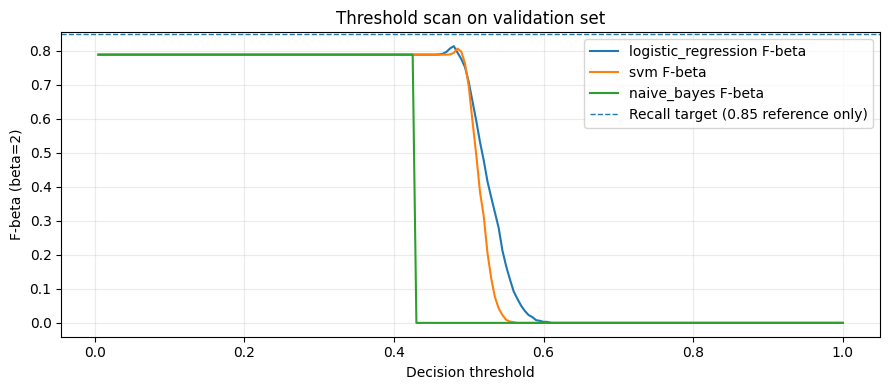

In [3]:
# Dò 200 ngưỡng trên Validation; Recall >= 0.85 là ràng buộc ưu tiên
threshold_optimizer = ThresholdOptimizerScratch(recall_target=0.85, beta=2.0, n_points=200)
threshold_results = {}
threshold_rows = []
for name, model in best_models.items():
    probabilities = model.predict_proba(X_val_csr)[:, 1]
    scan = threshold_optimizer.scan_thresholds(y_val, probabilities)
    best = threshold_optimizer.select_best_threshold(scan)
    threshold_results[name] = {"threshold": best["best_threshold"], "metrics": best, "scan": scan}
    threshold_rows.append({"model_name": name, **best})
threshold_summary = pd.DataFrame(threshold_rows).sort_values(["target_met", "f_beta", "f1"], ascending=False)
display(threshold_summary[["model_name", "best_threshold", "accuracy", "precision", "recall", "f1", "f_beta", "target_met"]].round(4))
fig, ax = plt.subplots(figsize=(9, 4))
for name, item in threshold_results.items():
    ax.plot(item["scan"]["threshold"], item["scan"]["f_beta"], label=f"{name} F-beta")
ax.axhline(0.85, linestyle="--", linewidth=1, label="Recall target (0.85 reference only)")
ax.set(xlabel="Decision threshold", ylabel="F-beta (beta=2)", title="Threshold scan on validation set")
ax.legend(); ax.grid(alpha=0.25); plt.tight_layout()
plt.savefig(FIGURES_DIR / "task2_threshold_tuning.png", dpi=300); plt.show()


## 3. Phương pháp kết hợp mô hình (Ensemble Methods)


In [4]:
# Voting Ensemble: dùng các mô hình đã fit bởi Grid Search
ensemble = SpamVotingEnsemble(best_models, voting="soft")
ensemble_prob = ensemble.predict_proba(X_val_csr)[:, 1]
ensemble_scan = threshold_optimizer.scan_thresholds(y_val, ensemble_prob)
ensemble_best_threshold = threshold_optimizer.select_best_threshold(ensemble_scan)
print("Soft Voting best threshold:", ensemble_best_threshold["best_threshold"])
print({k: ensemble_best_threshold[k] for k in ["accuracy", "precision", "recall", "f1", "f_beta", "target_met"]})

# Thử nghiệm thêm Random Forest và Gradient Boosting trên mẫu nhỏ, 300 đặc trưng đầu.
# Giới hạn mẫu/đặc trưng để tránh chuyển toàn bộ ma trận sparse lớn sang dense.
try:
    tree_models = build_tree_based_ensembles(random_state=42)
    n_rows, n_cols = min(2000, X_train_csr.shape[0]), min(300, X_train_csr.shape[1])
    X_tree_train = X_train_csr[:n_rows, :n_cols].toarray()
    y_tree_train = y_train[:n_rows]
    X_tree_val = X_val_csr[:min(500, X_val_csr.shape[0]), :n_cols].toarray()
    y_tree_val = y_val[:len(X_tree_val)]
    tree_rows = []
    for name, tree_model in tree_models.items():
        tree_model.fit(X_tree_train, y_tree_train)
        tree_prob = tree_model.predict_proba(X_tree_val)[:, 1]
        tree_pred = (tree_prob >= 0.5).astype(int)
        tree_rows.append({"model_name": name, "Accuracy": accuracy_score(y_tree_val, tree_pred),
                          "Precision": precision_score(y_tree_val, tree_pred, zero_division=0),
                          "Recall": recall_score(y_tree_val, tree_pred, zero_division=0),
                          "F1": f1_score(y_tree_val, tree_pred, zero_division=0),
                          "ROC-AUC": roc_auc_score(y_tree_val, tree_prob)})
    tree_experiment_summary = pd.DataFrame(tree_rows)
    display(tree_experiment_summary)
except Exception as exc:
    tree_experiment_summary = pd.DataFrame()
    print("Tree-based experiment could not be completed in this environment:", repr(exc))


Soft Voting best threshold: 0.465
{'accuracy': 0.5749224939717533, 'precision': 0.5010490977759127, 'recall': 0.9636803874092009, 'f1': 0.6593042517945886, 'f_beta': 0.8134623245673798, 'target_met': True}


,model_name,Accuracy,Precision,Recall,F1,ROC-AUC
0,random_forest,0.626,0.596859,0.508929,0.549398,0.704629
1,gradient_boosting,0.614,0.601307,0.410714,0.488064,0.672344


## 4. Lựa chọn mô hình chiến thắng (Final Model Selection)


In [5]:
# So sánh candidate và chọn mô hình thắng cuộc dựa trên validation
candidate_results = []
for name, model in best_models.items():
    probs = model.predict_proba(X_val_csr)[:, 1]
    threshold = threshold_results[name]["threshold"]
    pred = (probs >= threshold).astype(int)
    candidate_results.append({"model_name": name, "model": model, "best_threshold": threshold,
        "accuracy": accuracy_score(y_val, pred), "precision": precision_score(y_val, pred, zero_division=0),
        "recall": recall_score(y_val, pred, zero_division=0), "f1": f1_score(y_val, pred, zero_division=0),
        "f_beta": fbeta_score(y_val, pred, beta=2, zero_division=0), "roc_auc": roc_auc_score(y_val, probs)})
ensemble_pred = (ensemble_prob >= ensemble_best_threshold["best_threshold"]).astype(int)
candidate_results.append({"model_name": "soft_voting_ensemble", "model": ensemble,
    "best_threshold": ensemble_best_threshold["best_threshold"], "accuracy": accuracy_score(y_val, ensemble_pred),
    "precision": precision_score(y_val, ensemble_pred, zero_division=0), "recall": recall_score(y_val, ensemble_pred, zero_division=0),
    "f1": f1_score(y_val, ensemble_pred, zero_division=0), "f_beta": fbeta_score(y_val, ensemble_pred, beta=2, zero_division=0),
    "roc_auc": roc_auc_score(y_val, ensemble_prob)})
selection = ModelSelectionWorkflow(recall_target=0.85)
comparison_df = selection.compare_candidates(candidate_results)
display(comparison_df[["rank", "model_name", "best_threshold", "accuracy", "precision", "recall", "f1", "f_beta", "roc_auc", "target_met"]].round(4))
final_name = selection.select_final_winner(comparison_df)
winner = next(row for row in candidate_results if row["model_name"] == final_name)
final_selected_model = winner["model"]
best_threshold = float(winner["best_threshold"])
print(f"Selected model: {final_name}; threshold={best_threshold:.4f}; recall={winner['recall']:.4f}")

# Lưu artifact Task 2. Bộ text_processor/feature_builder chưa được Task 1 xuất thành artifact riêng,
# vì vậy notebook không tự fit lại chúng ở đây (bước này có thể tốn nhiều phút).
# Task 3 cần nhận builder đã fit từ Task 1 để phục vụ dự đoán email thô.
pipeline_bundle = {
    "model": final_selected_model,
    "final_selected_model": final_name,
    "best_threshold": best_threshold,
    "metadata": {"project": "Spam Email Classifier", "random_state": 42,
                 "recall_target": 0.85, "selection_metric": "F-beta (beta=2) on validation",
                 "validation_metrics": {k: float(winner[k]) for k in ["accuracy", "precision", "recall", "f1", "f_beta", "roc_auc"]},
                 "best_params": {"logistic_regression": lr_params, "svm": svm_params, "naive_bayes": nb_params},
                 "feature_builder_included": False,
                 "handoff_note": "Task 3 must attach the fitted Task 1 text_processor and feature_builder before raw-email inference."}
}
saved_path = save_spam_pipeline(pipeline_bundle)
print("Saved Task 2 model artifact:", saved_path)
print("Note: Task 1 fitted text_processor/feature_builder are not included in this repository as serialized objects.")


,rank,model_name,best_threshold,accuracy,precision,recall,f1,f_beta,roc_auc,target_met
0,1,soft_voting_ensemble,0.465,0.5749,0.5010,0.9637,0.6593,0.8135,0.6880,True
1,2,logistic_regression,0.480,0.5715,0.4990,0.9653,0.6579,0.8133,0.6875,True
2,3,svm,0.485,0.5088,0.4645,0.9879,0.6319,0.8062,0.6887,True
3,4,naive_bayes,0.005,0.4268,0.4268,1.0000,0.5983,0.7883,0.7442,True


Selected model: soft_voting_ensemble; threshold=0.4650; recall=0.9637
Saved Task 2 model artifact: /mnt/data/workspam/spam_classifier-main/results/saved_models/spam_pipeline.joblib
Note: Task 1 fitted text_processor/feature_builder are not included in this repository as serialized objects.
